# Project 3 — Predicting House Prices with Linear Regression

**Oasis Infobyte | Data Analytics track | Level 2 — Task 1**  
**Tools:** Python, pandas, NumPy, scikit-learn, Matplotlib, Seaborn, Jupyter Notebook

## Objective
Build and evaluate a Linear Regression model that predicts house prices from relevant housing attributes such as area, location, number of rooms, and age. The analysis covers data inspection, exploratory data analysis (EDA), feature selection, missing-value treatment, categorical encoding, an 80/20 train-test split, model evaluation, residual analysis, and coefficient interpretation.

## Dataset
The notebook first attempts to load the **Ames Housing / House Prices** dataset from OpenML. This dataset contains residential sale prices and a mixture of numeric and categorical property features. If OpenML is unavailable, the notebook tries a public Kaggle-style housing CSV mirror. If both sources are unavailable, it asks you to upload a compatible CSV file.

**Important:** The target price units and geography depend on the dataset source. This project is a learning exercise and should not be used as a live property valuation tool. The model learns patterns from historical data and does not establish causal relationships.

## Reproducibility
- Test split: 20% (80/20 split)
- Random seed: 42
- Missing numeric values: median imputation
- Missing categorical values: most-frequent imputation
- Categorical features: One-Hot Encoding
- Numeric features: median imputation and standardisation inside a scikit-learn pipeline

---

**Student:** Piyush Ramesh Bhor  
**Project:** Data Analytics — House Price Prediction

## 1. Import libraries and configure the notebook
We use pandas and NumPy for data handling, Seaborn/Matplotlib for visualisation, and scikit-learn for preprocessing, model training, and evaluation. All preprocessing is fitted inside a pipeline **after** the train-test split to reduce data leakage.

In [1]:
# If you see a missing-package error in Colab, run this once:
# !pip -q install pandas numpy matplotlib seaborn scikit-learn

import os
import warnings
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

OUTPUT_DIR = 'Project_3_House_Price_Outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Load the housing dataset
The preferred source is the Ames Housing / House Prices dataset from OpenML. If it cannot be downloaded, a public CSV mirror is attempted. As a last resort, Colab will open a file-upload prompt; upload a housing CSV containing a numeric target column named `SalePrice` or `price` (case-insensitive).

In [2]:
# Preferred dataset: Ames Housing / House Prices from OpenML
raw = None
dataset_source = None

try:
    housing = fetch_openml(name='house_prices', version=1, as_frame=True)
    if getattr(housing, 'frame', None) is not None:
        raw = housing.frame.copy()
    else:
        raw = pd.DataFrame(housing.data)
        if housing.target is not None:
            raw['SalePrice'] = housing.target
    dataset_source = 'OpenML: house_prices (Ames Housing)'
    print('Loaded dataset from', dataset_source)
except Exception as openml_error:
    print('OpenML download was not available:', type(openml_error).__name__)

# Fallback: a public CSV mirror with a numeric price target.
if raw is None:
    fallback_url = 'https://raw.githubusercontent.com/reisanar/datasets/master/kaggle-housing.csv'
    try:
        raw = pd.read_csv(fallback_url)
        dataset_source = 'Public CSV mirror: reisanar/datasets/kaggle-housing.csv'
        print('Loaded fallback dataset from', dataset_source)
    except Exception as csv_error:
        print('Automatic CSV download was not available:', type(csv_error).__name__)

# Final fallback: manual upload in Google Colab.
if raw is None:
    try:
        from google.colab import files
        print('Please upload a housing CSV with SalePrice or price as its target column.')
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError('No file was uploaded.')
        uploaded_name = next(iter(uploaded))
        raw = pd.read_csv(uploaded_name)
        dataset_source = f'Manually uploaded file: {uploaded_name}'
    except ImportError as exc:
        raise RuntimeError('Could not download the dataset. Please run this notebook in Colab and upload a CSV.') from exc

# Standardise column names while retaining the raw data in memory.
raw.columns = [str(c).strip().replace(' ', '_') for c in raw.columns]
print('\nDataset source:', dataset_source)
print('Dataset shape:', raw.shape)
display(raw.head())

Loaded dataset from OpenML: house_prices (Ames Housing)

Dataset source: OpenML: house_prices (Ames Housing)
Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,'Wd Sdng','Wd Shng',None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Initial inspection and data quality checks
We inspect column types, missing values, duplicate rows, and descriptive statistics. The target column is identified as `SalePrice` or `price`, ignoring capitalisation. Rows without a usable target value cannot be used for supervised model training and will be removed.

In [3]:
# Locate the target column without assuming its original capitalisation.
column_lookup = {str(c).strip().lower(): c for c in raw.columns}
if 'saleprice' in column_lookup:
    TARGET_COL = column_lookup['saleprice']
elif 'price' in column_lookup:
    TARGET_COL = column_lookup['price']
else:
    raise ValueError("Target column not found. Expected 'SalePrice' or 'price'. Check your uploaded CSV.")

print('Target column:', TARGET_COL)
print('\nData types:')
display(raw.dtypes.astype(str).rename('data_type').to_frame())

missing_before = raw.isna().sum().sort_values(ascending=False)
print('\nMissing values by column (top 20):')
display(missing_before.head(20).to_frame('missing_count'))
print('Duplicate rows:', int(raw.duplicated().sum()))
print('\nDescriptive statistics:')
display(raw.describe(include='all').T.head(35))

Target column: SalePrice

Data types:


,data_type
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
Street,object
Alley,object
LotShape,object
LandContour,object
Utilities,object



Missing values by column (top 20):


,missing_count
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
FireplaceQu,690
LotFrontage,259
GarageFinish,81
GarageQual,81
GarageYrBlt,81
GarageType,81


Duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1460.0,NaN,NaN,NaN,730.5,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,NaN,NaN,NaN,56.89726,42.300571,20.0,20.0,50.0,70.0,190.0
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,1201.0,NaN,NaN,NaN,70.049958,24.284752,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,NaN,NaN,NaN,10516.828082,9981.264932,1300.0,7553.5,9478.5,11601.5,215245.0
Street,1460,2,Pave,1454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Alley,91,2,Grvl,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotShape,1460,4,Reg,925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LandContour,1460,4,Lvl,1311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Utilities,1460,2,AllPub,1459,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Prepare the modelling table
The target is converted to numeric and rows with missing target values are removed. Exact duplicate records are removed. Identifier columns such as `Id` are dropped because they are row identifiers rather than meaningful house attributes. Feature columns with more than 50% missing values are excluded to avoid relying on extremely sparse fields; remaining missing values are imputed in the model pipeline.

In [4]:
df = raw.copy()
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors='coerce')
rows_before = len(df)
df = df.dropna(subset=[TARGET_COL]).drop_duplicates().copy()
rows_after_target_and_duplicates = len(df)

# Drop common identifier columns if present.
id_candidates = [c for c in df.columns if str(c).strip().lower() in {'id', 'unnamed:_0', 'unnamed:0'}]
if id_candidates:
    df = df.drop(columns=id_candidates)

# Exclude columns that are more than 50% missing; record them for reporting.
missing_ratio = df.drop(columns=[TARGET_COL]).isna().mean()
high_missing_columns = missing_ratio[missing_ratio > 0.50].index.tolist()
if high_missing_columns:
    df = df.drop(columns=high_missing_columns)

# Replace infinite numeric values with NaN so the pipeline can impute them.
num_cols_initial = df.select_dtypes(include=np.number).columns
if len(num_cols_initial):
    df[num_cols_initial] = df[num_cols_initial].replace([np.inf, -np.inf], np.nan)

# Remove features that are completely empty after the preceding steps.
all_missing_columns = [c for c in df.columns if c != TARGET_COL and df[c].isna().all()]
if all_missing_columns:
    df = df.drop(columns=all_missing_columns)

X = df.drop(columns=[TARGET_COL]).copy()
y = df[TARGET_COL].copy()

print('Rows before target/duplicate cleaning:', rows_before)
print('Rows after target/duplicate cleaning:', rows_after_target_and_duplicates)
print('Identifier columns dropped:', id_candidates)
print('Columns dropped for >50% missing:', high_missing_columns)
print('All-missing columns dropped:', all_missing_columns)
print('Final modelling table:', X.shape)
print('Target summary:')
display(y.describe().to_frame('house_price'))

Rows before target/duplicate cleaning: 1460
Rows after target/duplicate cleaning: 1460
Identifier columns dropped: ['Id']
Columns dropped for >50% missing: ['Alley', 'PoolQC', 'Fence', 'MiscFeature']
All-missing columns dropped: []
Final modelling table: (1460, 75)
Target summary:


,house_price
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


## 5. Exploratory Data Analysis (EDA)
We inspect the price distribution and compare numeric predictors with the target. For highly skewed house-price data, the histogram may show a long right tail. Correlations describe linear association only and should not be interpreted as proof that one feature causes a price change.

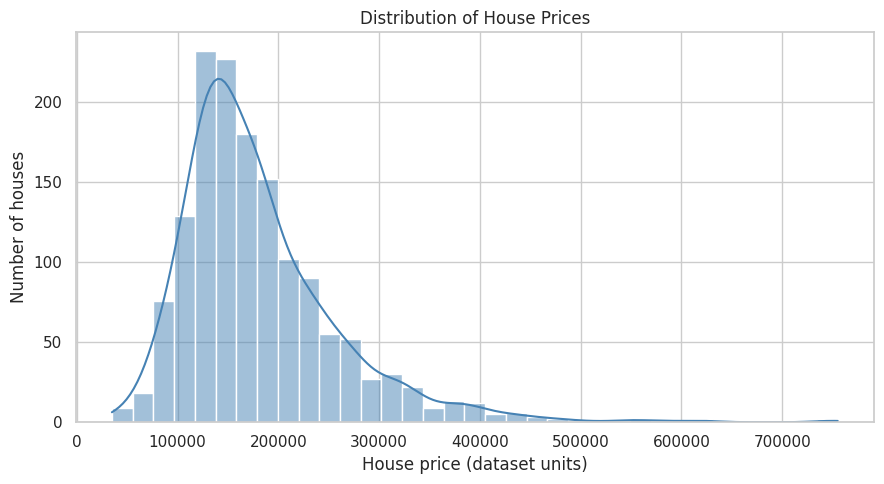

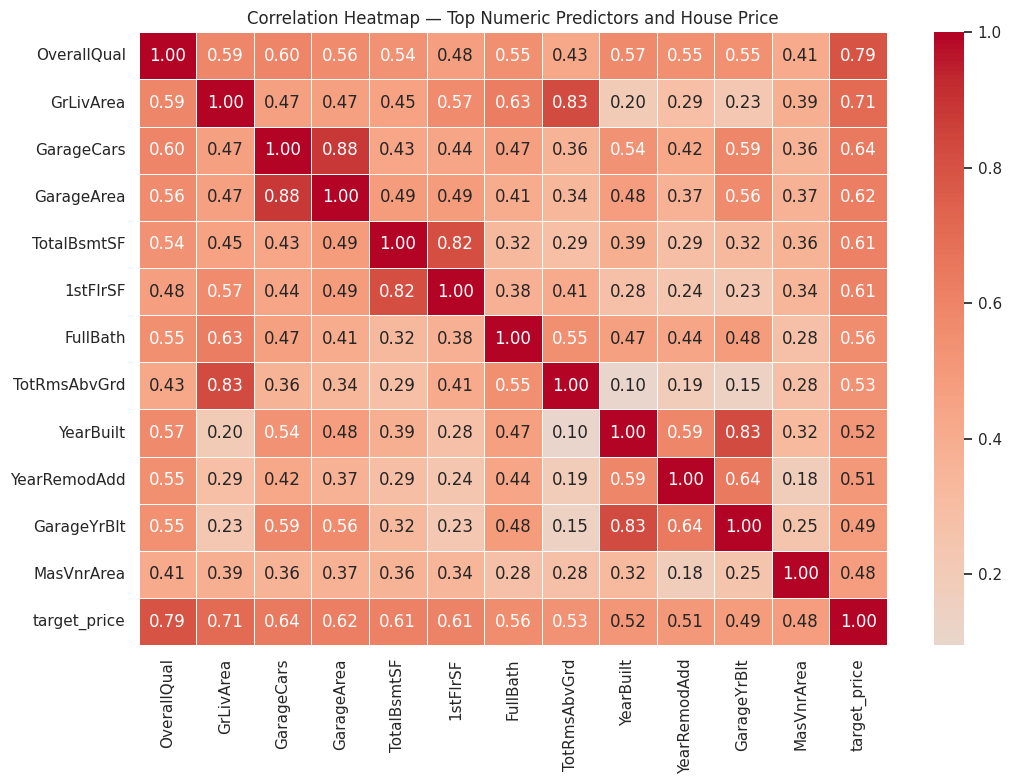

Numeric predictors most correlated with price (correlation is not causation):


,correlation_with_price
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [5]:
# Target distribution
plt.figure(figsize=(9, 5))
sns.histplot(y, bins=35, kde=True, color='steelblue')
plt.title('Distribution of House Prices')
plt.xlabel('House price (dataset units)')
plt.ylabel('Number of houses')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/01_house_price_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

numeric_X = X.select_dtypes(include=np.number)
if numeric_X.shape[1] > 0:
    numeric_corr = pd.concat([numeric_X, y.rename('target_price')], axis=1).corr(numeric_only=True)
    target_corr = numeric_corr['target_price'].drop('target_price').dropna().sort_values(key=lambda s: s.abs(), ascending=False)
    top_corr_features = target_corr.head(min(12, len(target_corr))).index.tolist()
    plt.figure(figsize=(11, 8))
    sns.heatmap(numeric_corr.loc[top_corr_features + ['target_price'], top_corr_features + ['target_price']],
                annot=True, cmap='coolwarm', center=0, fmt='.2f', linewidths=.4)
    plt.title('Correlation Heatmap — Top Numeric Predictors and House Price')
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/02_correlation_heatmap.png', dpi=160, bbox_inches='tight')
    plt.show()
    print('Numeric predictors most correlated with price (correlation is not causation):')
    display(target_corr.head(10).rename('correlation_with_price').to_frame())
else:
    print('No numeric predictor columns were found; EDA correlation heatmap skipped.')

## 6. Feature selection discussion
Potential predictors are chosen because they describe a property's size, capacity, age, condition, location, or facilities. Examples in the Ames dataset include `LotArea`, `OverallQual`, `YearBuilt`, `GrLivArea`, `TotalBsmtSF`, `GarageCars`, and `Neighborhood`. In a different housing CSV, relevant fields may instead include `area`, `bedrooms`, `bathrooms`, `stories`, `mainroad`, `prefarea`, or `furnishingstatus`.

This notebook uses all available non-ID features as candidate predictors, then uses EDA and the fitted model coefficients to discuss their relationship with price. This is a transparent baseline rather than an automatic claim that every feature is useful.

## 7. Train-test split and preprocessing
We reserve 20% of the rows for testing and train on the remaining 80%. Numeric columns use median imputation and standardisation. Categorical columns use most-frequent imputation followed by One-Hot Encoding. The `Pipeline` ensures preprocessing is fitted only on the training data, preventing information from the test set leaking into the model.

In [6]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
print('Numeric features:', len(numeric_features))
print('Categorical features:', len(categorical_features))
print('Categorical columns sample:', categorical_features[:20])

if len(numeric_features) + len(categorical_features) == 0:
    raise ValueError('No usable predictor columns remain after data preparation.')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

transformers = []
if numeric_features:
    transformers.append(('num', numeric_transformer, numeric_features))
if categorical_features:
    transformers.append(('cat', categorical_transformer, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder='drop')

linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])
linear_model.fit(X_train, y_train)
print('Linear Regression model trained successfully.')

Numeric features: 36
Categorical features: 39
Categorical columns sample: ['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation']
Training rows: 1168
Testing rows: 292
Linear Regression model trained successfully.


## 8. Evaluate the Linear Regression model
We evaluate predictions on the unseen test set using the metrics requested in the task: Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R². MAE is included as an additional, easy-to-interpret error measure. Lower MSE/RMSE/MAE indicates smaller prediction errors; R² closer to 1 indicates that the model explains more of the variation in the test-set target. A negative R² means the model performs worse than predicting the test-set mean.

In [7]:
predictions = linear_model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
rmse = float(np.sqrt(mse))
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

metrics = pd.DataFrame({
    'Metric': ['MSE', 'RMSE', 'MAE', 'R-squared'],
    'Value': [mse, rmse, mae, r2]
})
display(metrics.style.format({'Value': '{:,.4f}'}))
print(f'Test-set MSE: {mse:,.3f}')
print(f'Test-set RMSE: {rmse:,.3f}')
print(f'Test-set MAE: {mae:,.3f}')
print(f'Test-set R-squared: {r2:.4f}')

,Metric,Value
0,MSE,"2,729,849,625.2843"
1,RMSE,"52,247.9629"
2,MAE,"20,509.7592"
3,R-squared,0.6441


Test-set MSE: 2,729,849,625.284
Test-set RMSE: 52,247.963
Test-set MAE: 20,509.759
Test-set R-squared: 0.6441


## 9. Actual vs. predicted house prices
Points close to the 45-degree diagonal line represent predictions close to the observed prices. Large vertical distances from the line indicate larger prediction errors. The chart should be interpreted together with RMSE and R², not in isolation.

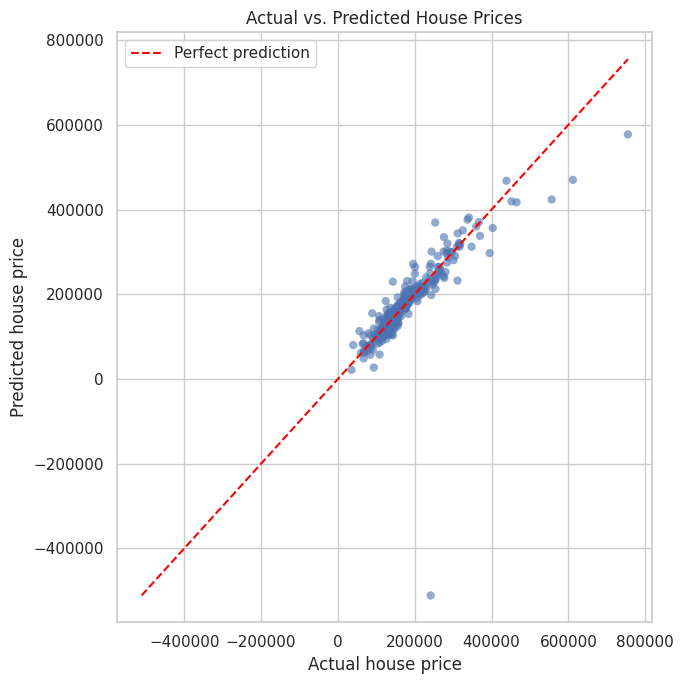

In [8]:
plot_min = float(min(y_test.min(), predictions.min()))
plot_max = float(max(y_test.max(), predictions.max()))
plt.figure(figsize=(7, 7))
plt.scatter(y_test, predictions, alpha=0.60, edgecolor='none')
plt.plot([plot_min, plot_max], [plot_min, plot_max], color='red', linestyle='--', label='Perfect prediction')
plt.title('Actual vs. Predicted House Prices')
plt.xlabel('Actual house price')
plt.ylabel('Predicted house price')
plt.legend()
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/03_actual_vs_predicted.png', dpi=160, bbox_inches='tight')
plt.show()

## 10. Residual analysis
A residual is `actual price − predicted price`. Residuals should ideally be scattered around zero without a clear curve or funnel shape. Visible structure may indicate non-linearity, unequal error variance, omitted variables, or outliers. This diagnostic helps identify where a simple Linear Regression model may be insufficient.

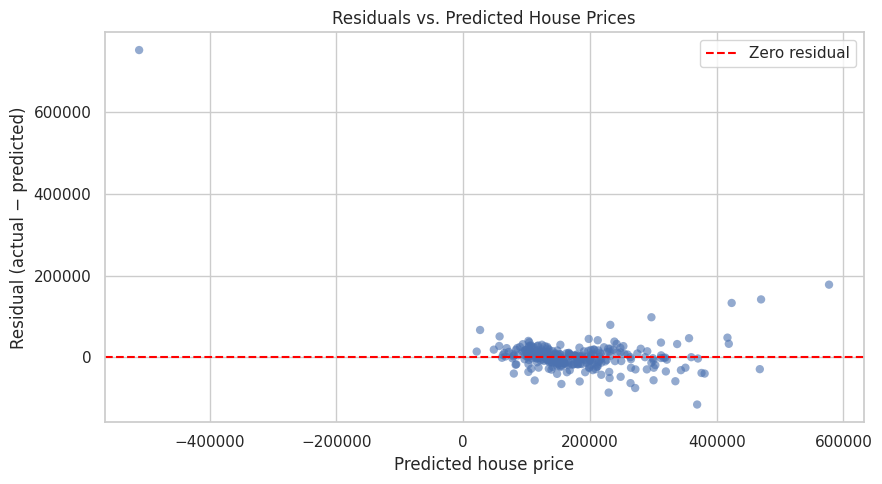

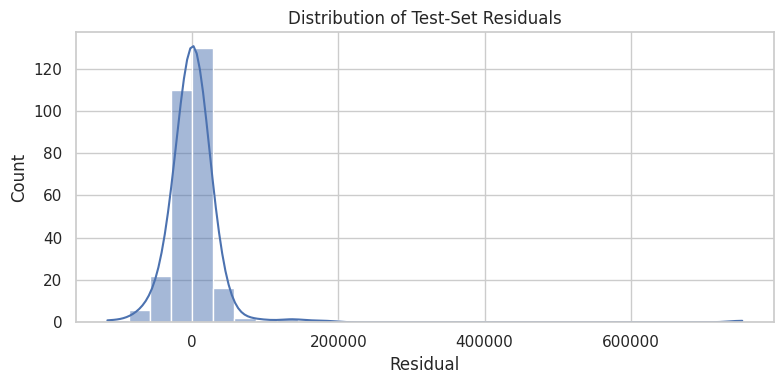

In [9]:
residuals = y_test.to_numpy() - predictions
plt.figure(figsize=(9, 5))
plt.scatter(predictions, residuals, alpha=0.60, edgecolor='none')
plt.axhline(0, color='red', linestyle='--', label='Zero residual')
plt.title('Residuals vs. Predicted House Prices')
plt.xlabel('Predicted house price')
plt.ylabel('Residual (actual − predicted)')
plt.legend()
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/04_residual_plot.png', dpi=160, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=30, kde=True)
plt.title('Distribution of Test-Set Residuals')
plt.xlabel('Residual')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/05_residual_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

## 11. Coefficient analysis and interpretation
The numeric predictors are standardised before fitting. Therefore, a numeric coefficient estimates the change in predicted price associated with a **one-standard-deviation increase** in that feature, holding the other encoded features fixed. One-hot encoded category coefficients compare a category with its omitted reference category. Coefficients are associations within this model and are not causal effects.

Largest positive coefficients:


,feature,coefficient,absolute_coefficient
0,cat__RoofMatl_Metal,719223.887177,719223.887177
1,cat__RoofMatl_WdShngl,685475.166335,685475.166335
2,cat__RoofMatl_Tar&Grv,676264.520589,676264.520589
3,cat__RoofMatl_CompShg,674919.847763,674919.847763
4,cat__RoofMatl_WdShake,673833.181793,673833.181793
5,cat__RoofMatl_Roll,672949.975551,672949.975551
11,cat__GarageCond_TA,147927.433816,147927.433816
12,cat__GarageCond_Fa,145895.840067,145895.840067
13,cat__GarageCond_Gd,144372.255688,144372.255688
14,cat__GarageCond_Po,142541.372954,142541.372954


Largest negative coefficients:


,feature,coefficient,absolute_coefficient
6,cat__Condition2_PosN,-234218.143167,234218.143167
7,cat__GarageQual_Po,-166079.690446,166079.690446
8,cat__GarageQual_Fa,-156621.571521,156621.571521
9,cat__GarageQual_Gd,-153615.554304,153615.554304
10,cat__GarageQual_TA,-150864.947290,150864.947290
15,cat__Condition2_RRAe,-98761.218688,98761.218688
18,cat__Functional_Sev,-62170.765984,62170.765984
20,cat__Exterior1st_ImStucc,-49253.562513,49253.562513
22,cat__LandSlope_Sev,-44303.598914,44303.598914
23,cat__Heating_OthW,-34090.289847,34090.289847


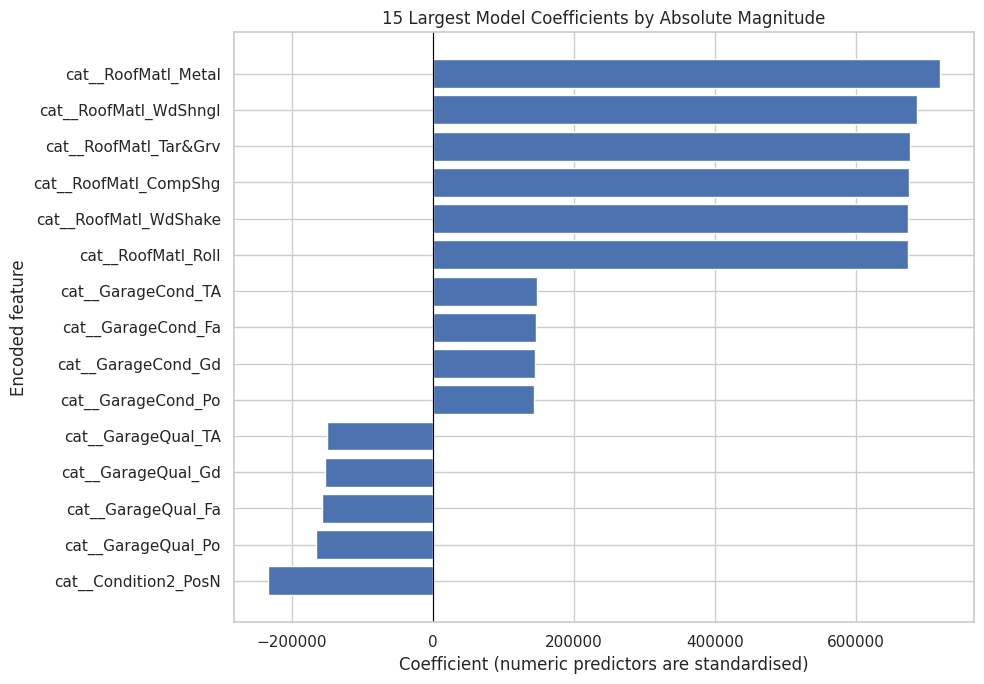

In [10]:
feature_names = linear_model.named_steps['preprocessor'].get_feature_names_out()
coefficients = linear_model.named_steps['regressor'].coef_
coef_table = pd.DataFrame({'feature': feature_names, 'coefficient': coefficients})
coef_table['absolute_coefficient'] = coef_table['coefficient'].abs()
coef_table = coef_table.sort_values('absolute_coefficient', ascending=False).reset_index(drop=True)

print('Largest positive coefficients:')
display(coef_table.sort_values('coefficient', ascending=False).head(10))
print('Largest negative coefficients:')
display(coef_table.sort_values('coefficient', ascending=True).head(10))

# Visualise the coefficients with largest absolute magnitude.
coef_plot = coef_table.head(15).sort_values('coefficient')
plt.figure(figsize=(10, 7))
plt.barh(coef_plot['feature'], coef_plot['coefficient'])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('15 Largest Model Coefficients by Absolute Magnitude')
plt.xlabel('Coefficient (numeric predictors are standardised)')
plt.ylabel('Encoded feature')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/06_top_model_coefficients.png', dpi=160, bbox_inches='tight')
plt.show()

## 12. Optional: compare Ridge Regression
Ridge Regression adds L2 regularisation and can help control large coefficients when predictors are correlated. This is an optional comparison; Linear Regression remains the required primary model. Both models use the same train-test split and preprocessing strategy.

In [11]:
ridge_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=10.0))
])
ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_test)

comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression'],
    'MSE': [mean_squared_error(y_test, predictions), mean_squared_error(y_test, ridge_predictions)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, predictions)), np.sqrt(mean_squared_error(y_test, ridge_predictions))],
    'MAE': [mean_absolute_error(y_test, predictions), mean_absolute_error(y_test, ridge_predictions)],
    'R2': [r2_score(y_test, predictions), r2_score(y_test, ridge_predictions)]
})
display(comparison.style.format({'MSE':'{:,.3f}', 'RMSE':'{:,.3f}', 'MAE':'{:,.3f}', 'R2':'{:.4f}'}))

,Model,MSE,RMSE,MAE,R2
0,Linear Regression,"2,729,849,625.284","52,247.963","20,509.759",0.6441
1,Ridge Regression,"943,245,009.299","30,712.294","18,913.834",0.8770


## 13. Data-driven findings and business recommendations
The following code creates a short summary from the actual model run. Review the output and add your own explanation in the final report. Do not claim the model is suitable for real estate lending or live valuations without further validation.

In [12]:
# Top numeric correlations and model coefficients are derived from the loaded dataset.
print('DATASET:', dataset_source)
print(f'Rows used for modelling: {len(df):,}')
print(f'Predictor columns before encoding: {X.shape[1]:,}')
print(f'Test-set RMSE: {rmse:,.3f} price units')
print(f'Test-set R-squared: {r2:.4f}')

if numeric_X.shape[1] > 0 and len(target_corr) > 0:
    top_feature = target_corr.index[0]
    top_value = target_corr.iloc[0]
    print(f'\nStrongest numeric linear association with price: {top_feature} (correlation = {top_value:.3f}).')

positive_coef = coef_table.sort_values('coefficient', ascending=False).head(3)
negative_coef = coef_table.sort_values('coefficient', ascending=True).head(3)
print('\nThree largest positive model coefficients:')
for _, row in positive_coef.iterrows():
    print(f"- {row['feature']}: {row['coefficient']:.3f}")
print('\nThree largest negative model coefficients:')
for _, row in negative_coef.iterrows():
    print(f"- {row['feature']}: {row['coefficient']:.3f}")

print('\nBusiness recommendations to consider:')
print('1. Use the strongest numeric associations as a starting point for property feature review, not as proof of causation.')
print('2. Collect complete, consistent location, size, age, and condition information to improve future model reliability.')
print('3. Review large residuals separately; the model may underpredict or overpredict particular property segments.')
print('4. Validate the model on more recent and geographically relevant transactions before any real-world use.')

DATASET: OpenML: house_prices (Ames Housing)
Rows used for modelling: 1,460
Predictor columns before encoding: 75
Test-set RMSE: 52,247.963 price units
Test-set R-squared: 0.6441

Strongest numeric linear association with price: OverallQual (correlation = 0.791).

Three largest positive model coefficients:
- cat__RoofMatl_Metal: 719223.887
- cat__RoofMatl_WdShngl: 685475.166
- cat__RoofMatl_Tar&Grv: 676264.521

Three largest negative model coefficients:
- cat__Condition2_PosN: -234218.143
- cat__GarageQual_Po: -166079.690
- cat__GarageQual_Fa: -156621.572

Business recommendations to consider:
1. Use the strongest numeric associations as a starting point for property feature review, not as proof of causation.
2. Collect complete, consistent location, size, age, and condition information to improve future model reliability.
3. Review large residuals separately; the model may underpredict or overpredict particular property segments.
4. Validate the model on more recent and geographically

## 14. Export project outputs
The output folder contains the model metrics, test-set predictions, coefficient table, model comparison, and charts. In Colab, the code also creates a ZIP archive for download.

In [13]:
prediction_output = pd.DataFrame({
    'actual_price': y_test.reset_index(drop=True),
    'predicted_price': predictions,
    'residual': residuals
})

metrics.to_csv(f'{OUTPUT_DIR}/model_metrics.csv', index=False)
comparison.to_csv(f'{OUTPUT_DIR}/model_comparison.csv', index=False)
prediction_output.to_csv(f'{OUTPUT_DIR}/test_set_predictions.csv', index=False)
coef_table.to_csv(f'{OUTPUT_DIR}/model_coefficients.csv', index=False)

run_summary = pd.DataFrame([{
    'dataset_source': dataset_source,
    'target_column': TARGET_COL,
    'rows_used': len(df),
    'predictor_columns_before_encoding': X.shape[1],
    'train_rows': len(X_train),
    'test_rows': len(X_test),
    'mse': mse,
    'rmse': rmse,
    'mae': mae,
    'r2': r2
}])
run_summary.to_csv(f'{OUTPUT_DIR}/run_summary.csv', index=False)

zip_path = 'Project_3_House_Price_Outputs.zip'
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for root, _, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            zf.write(full_path, arcname=os.path.relpath(full_path, OUTPUT_DIR))

print('Saved files:')
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print('-', filename)
print('\nCreated archive:', zip_path)

# Optional automatic download in Google Colab. Uncomment if needed:
# from google.colab import files
# files.download(zip_path)

Saved files:
- 01_house_price_distribution.png
- 02_correlation_heatmap.png
- 03_actual_vs_predicted.png
- 04_residual_plot.png
- 05_residual_distribution.png
- 06_top_model_coefficients.png
- model_coefficients.csv
- model_comparison.csv
- model_metrics.csv
- run_summary.csv
- test_set_predictions.csv

Created archive: Project_3_House_Price_Outputs.zip


## 15. Final report — completed after execution

### Objective and dataset
This project builds a regression model to estimate residential sale prices from property attributes. The run used the **OpenML `house_prices` (Ames Housing) dataset**. The modelling table contains **1,460 houses** and **75 predictor columns** before encoding. The target is `SalePrice`, the recorded historical sale price in the dataset. These records represent a single historical housing market and should not be treated as current market values or as representative of other locations.

### Data preparation and feature selection
The initial dataset contained 1,460 rows and 81 columns (including the identifier and target). The `Id` identifier was excluded because it is not a meaningful property characteristic. Four predictors with more than 50% missing values (`Alley`, `PoolQC`, `Fence`, and `MiscFeature`) were removed. No rows were removed for a missing target or exact duplicate records in this run. The remaining predictors comprised 36 numeric and 39 categorical columns.

Preprocessing was fitted on the training data only through a scikit-learn pipeline. Numeric missing values were filled with the **median** and the numeric features were standardised. Categorical missing values were filled with the **most frequent** value and categorical variables were transformed using **One-Hot Encoding** (`drop='first'`). The data was split into **1,168 training rows (80%) and 292 test rows (20%)** using `random_state=42`.

The EDA showed the strongest numeric linear association with sale price was `OverallQual` (correlation **0.791**), followed by `GrLivArea` (**0.709**), `GarageCars` (**0.640**), `GarageArea` (**0.623**) and `TotalBsmtSF` (**0.614**). Correlation indicates association, not causation. These features are reasonable candidates because they describe overall construction quality, usable living area, garage capacity/size and basement area.

### Linear Regression model and test results
The required **Linear Regression** model was trained on the 80% training split and evaluated on the held-out 20% test split:

| Metric | Test result |
|---|---:|
| Mean Squared Error (MSE) | 2,729,849,625.284 |
| Root Mean Squared Error (RMSE) | 52,247.963 price units |
| Mean Absolute Error (MAE) | 20,509.759 price units |
| R-squared (R²) | 0.6441 |

The R² value means this baseline model explains approximately **64.41% of the variation** in the held-out sale prices for this split. The RMSE is larger than the MAE, indicating that a small number of large prediction errors have a strong effect on squared error.

### Actual-versus-predicted and residual analysis
Most points in the actual-versus-predicted plot cluster around the 45-degree reference line, so many predictions are reasonably close to the observed prices. However, there are noticeable deviations for some expensive properties and one particularly extreme prediction below zero. Negative predicted house prices are not meaningful. This is a warning that the unregularised Linear Regression baseline is unstable for at least some rows, likely due to the high-dimensional encoded feature space and rare categories.

The residual plot contains a very large positive residual and shows wider errors among some higher predicted-price observations. The residuals are therefore not perfectly random or evenly distributed around zero. This suggests that the simple linear model does not capture every relationship in the dataset and that unusual records/categories can have substantial influence.

### Coefficient interpretation
The largest positive coefficient in the fitted one-hot encoded model was `cat__RoofMatl_Metal` (**+719,223.887**); the largest negative coefficient was `cat__Condition2_PosN` (**−234,218.143**). Numeric coefficients are expressed per one-standard-deviation increase because numeric predictors were standardised. One-hot coefficients compare a category with its omitted reference category.

These extreme categorical coefficients should **not** be interpreted as general price effects. Some categories are rare, and coefficients in a model with many correlated or sparse encoded features can be unstable. The numeric correlation results (especially `OverallQual` and `GrLivArea`) provide a more cautious descriptive signal, but they still do not establish causal effects.

### Optional Ridge Regression comparison
The notebook also fitted Ridge Regression on the same split as an optional regularised comparison:

| Model | MSE | RMSE | MAE | R² |
|---|---:|---:|---:|---:|
| Linear Regression | 2,729,849,625.284 | 52,247.963 | 20,509.759 | 0.6441 |
| Ridge Regression (alpha=10) | 943,245,009.299 | 30,712.294 | 18,913.834 | 0.8770 |

For this run, Ridge Regression achieved a lower error and higher R² than ordinary Linear Regression. This supports the concern that regularisation helps control coefficient instability in this feature set. **Linear Regression remains the required primary task model; Ridge is an additional comparison, not a replacement for reporting the required model.**

### Business recommendations
1. **Prioritise accurate property-quality and size records.** The strongest numeric associations in this dataset were `OverallQual` and `GrLivArea`; property records should capture these fields consistently.
2. **Investigate large prediction errors.** Review unusually large residuals and uncommon property categories before using model predictions in any workflow.
3. **Use regularisation as a model-improvement candidate.** Ridge performed better than ordinary Linear Regression on this hold-out split, so compare regularised and baseline models during further development.
4. **Validate on newer and geographically relevant data.** Before using any model for a business decision, test it on more recent local transactions and monitor performance over time.

### Limitations
- The dataset is historical and geographically specific; the results may not generalise to another city, country or current market.
- Linear Regression models additive linear relationships in the transformed features and may miss complex interactions and nonlinear effects.
- The one-hot encoded feature set contains rare categories; extreme coefficients and the negative prediction show that the unregularised model can be unstable for some observations.
- A single 80/20 split provides one estimate of performance. Cross-validation and external validation would provide stronger evidence.
- Correlations and model coefficients are associations, not proof of causation.
- This model is a learning exercise and must not be used as a live valuation, lending, or investment decision tool without substantial validation.

### Conclusion
The project completed the required end-to-end regression workflow: data inspection, EDA, feature discussion, missing-value preprocessing, one-hot encoding, an 80/20 split, Linear Regression training, MSE/RMSE/R² evaluation, actual-versus-predicted visualisation, residual analysis and coefficient interpretation. The baseline Linear Regression achieved **R² = 0.6441** on the test set. The optional Ridge comparison improved the test-set R² to **0.8770** and reduced RMSE from **52,247.963** to **30,712.294** price units on the same split. These results are specific to this dataset and split; further validation is necessary before practical deployment.
